# Open Based Supply

## Run this example in [Colab](https://colab.research.google.com/github/SignalOceanSdk/SignalSDK/blob/master/docs/examples/jupyter/SupplyAPI/OpenBasedSupply.ipynb)

Which Aframax tankers open in Houston in the next 20 days, with commercial data updated in the last 5 days?

## Setup
Install the Signal Ocean SDK:
```
pip install signal-ocean
```
You need your own API key with access to the Supply API, for the vessel classes that you query. Get your key here: https://apis.signalocean.com/profile

In [ ]:
!pip install signal-ocean

In [2]:
signal_ocean_api_key = ''  # Replace with your subscription key

In [3]:
from datetime import date

from signal_ocean import Connection
from signal_ocean.supply import (
    CommercialAvailabilityFilter,
    FromToRange,
    GeoLocation,
    IncludeExcludeFilter,
    LocationTaxonomy,
    SupplyAPI,
    SupplyFilter,
    VesselClass,
)

connection = Connection(signal_ocean_api_key)
api = SupplyAPI(connection)

## Filters
- `open_location`: Houston, the port with geo id 3853.
- `open_date_relative_offset`: open from 5 days ago up to 20 days ahead.
- `latest_updated_date_relative_offset`: updated in the last 5 days.

Relative offsets count days from each snapshot day on the trend, and from today on live supply.

In [4]:
houston = GeoLocation(geo_id=3853, location_taxonomy=LocationTaxonomy.PORT)

filters = SupplyFilter(
    vessel_class=VesselClass.AFRAMAX,
    commercial_availability=CommercialAvailabilityFilter(
        open_location=IncludeExcludeFilter(values=[houston]),
        open_date_relative_offset=FromToRange(from_=-5, to=20),
        latest_updated_date_relative_offset=FromToRange(from_=-5, to=0),
    ),
)

## Supply trend

In [5]:
trend_frame = api.get_supply_trend(date(2026, 8, 1), date(2026, 10, 31), filters=filters).to_data_frame()
trend_frame.tail()

,supply
date,
2026-10-27,37
2026-10-28,43
2026-10-29,39
2026-10-30,38
2026-10-31,35


<Axes: title={'center': 'Aframax tankers opening in Houston within 20 days'}, ylabel='Vessels'>

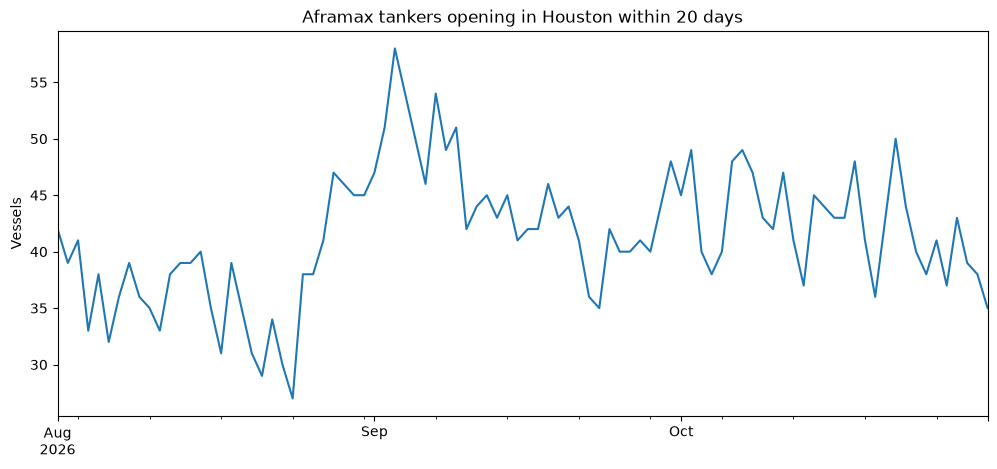

In [6]:
trend_frame.plot(y="supply", figsize=(12, 5), legend=False,
    title="Aframax tankers opening in Houston within 20 days", ylabel="Vessels", xlabel="")

## The vessels now, by open date

In [7]:
live_frame = api.get_live_supply(filters=filters).to_data_frame()
live_frame.sort_values("open_date_to")[
    ["imo", "open_location", "open_date_from", "open_date_to",
     "availability_state", "latest_updated_date"]
]

,imo,open_location,open_date_from,open_date_to,availability_state,latest_updated_date
8,9439395,US Gulf,2026-11-11 09:24:46.000+00:00,2026-11-11 09:24:46.000+00:00,PotentiallyFixed,2026-11-11 10:16:07.920606+00:00
31,9645401,US Gulf,2026-11-11 09:32:58.000+00:00,2026-11-11 09:32:58.000+00:00,OnSubs,2026-11-11 10:04:35.328236+00:00
25,9624067,US Gulf,2026-11-11 09:39:06.000+00:00,2026-11-11 09:39:06.000+00:00,Available,2026-11-11 10:17:56.079665+00:00
15,9777943,US Gulf,2026-11-11 09:40:41.000+00:00,2026-11-11 09:40:41.000+00:00,Available,2026-11-11 10:16:26.370373+00:00
1,1020930,US Gulf,2026-11-11 09:40:54.000+00:00,2026-11-11 09:40:54.000+00:00,Available,2026-11-11 10:15:52.726078+00:00
5,9488023,US Gulf,2026-11-11 09:42:37.000+00:00,2026-11-11 09:42:37.000+00:00,PotentiallyFixed,2026-11-11 10:16:24.491805+00:00
22,1071434,US Gulf,2026-11-11 09:43:06.000+00:00,2026-11-11 09:43:06.000+00:00,Available,2026-11-11 10:16:02.770129+00:00
24,9518892,US Gulf,2026-11-11 09:44:49.000+00:00,2026-11-11 09:44:49.000+00:00,Available,2026-11-11 10:16:21.867342+00:00
2,9414034,US Gulf,2026-11-11 09:46:45.000+00:00,2026-11-11 09:46:45.000+00:00,Available,2026-11-11 10:16:06.035337+00:00
6,9863417,US Gulf,2026-11-11 09:47:16.000+00:00,2026-11-11 09:47:16.000+00:00,PotentiallyFixed,2026-11-11 10:17:26.617904+00:00


In [8]:
connection.close()